In [1]:
pip install pandas numpy scikit-learn matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

# Load math dataset
df = pd.read_csv(r"C:\Users\gsshr\Documents\student-performance-ml\data\raw\student-mat.csv", sep=";")

print("Shape:", df.shape)
df.head()

Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
# Create the binary target: 1 = Pass, 0 = At-Risk / Fail
df["passed"] = (df["G3"] >= 10).astype(int)

# Check the distribution
counts = df["passed"].value_counts()
percentages = df["passed"].value_counts(normalize=True) * 100

print(f"Total Students: {len(df)}")
print(f"Passed (Class 1)   : {counts[1]} ({percentages[1]:.2f}%)")
print(f"At-Risk (Class 0)  : {counts[0]} ({percentages[0]:.2f}%)")

Total Students: 395
Passed (Class 1)   : 265 (67.09%)
At-Risk (Class 0)  : 130 (32.91%)


Correlation with 'passed':
passed        1.000000
G3            0.770042
G2            0.725407
G1            0.664979
Medu          0.115396
Fedu          0.108057
studytime     0.074613
famrel        0.046683
freetime     -0.018321
Walc         -0.029957
traveltime   -0.044446
Dalc         -0.057343
health       -0.065668
absences     -0.092244
age          -0.179645
goout        -0.183399
failures     -0.337731
Name: passed, dtype: float64


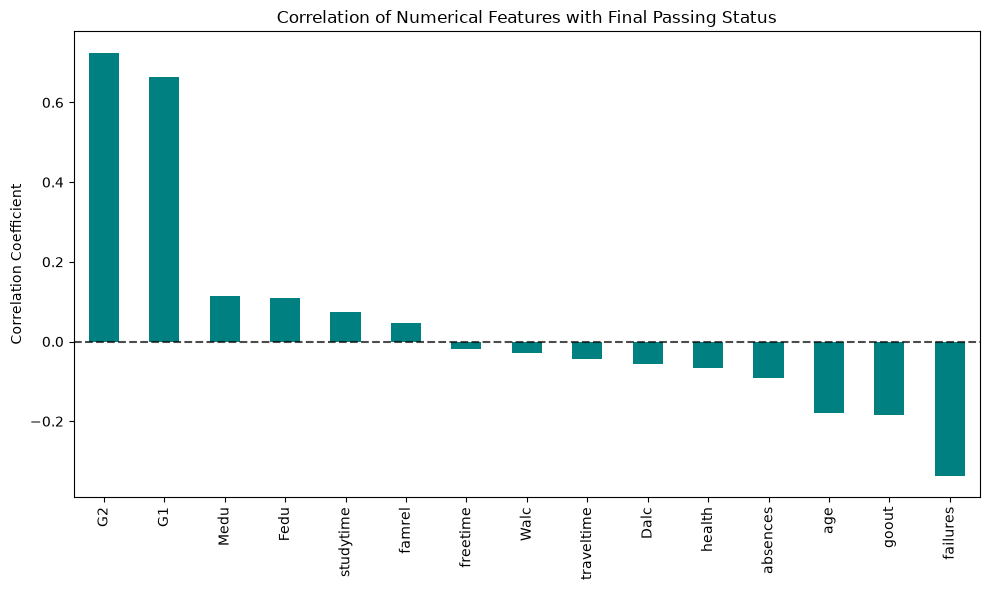

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns

# Correlation with target
corr_matrix = df[numerical_cols].corr()
target_corr = corr_matrix["passed"].sort_values(ascending=False)

print("Correlation with 'passed':")
print(target_corr)

# Plot correlation bar chart
plt.figure(figsize=(10, 6))
target_corr.drop(["passed", "G3"]).plot(kind="bar", color="teal")
plt.title("Correlation of Numerical Features with Final Passing Status")
plt.ylabel("Correlation Coefficient")
plt.axhline(0, color="black", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

C:\Users\gsshr\AppData\Local\Temp\ipykernel_25292\3426130590.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=failure_pass_rate.index, y=failure_pass_rate.values, ax=axes[0], palette="Blues_r")
C:\Users\gsshr\AppData\Local\Temp\ipykernel_25292\3426130590.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="passed", y="absences", data=df, ax=axes[1], palette="Set2")
C:\Users\gsshr\AppData\Local\Temp\ipykernel_25292\3426130590.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(["At-Risk (0)", "Passed (1)"])


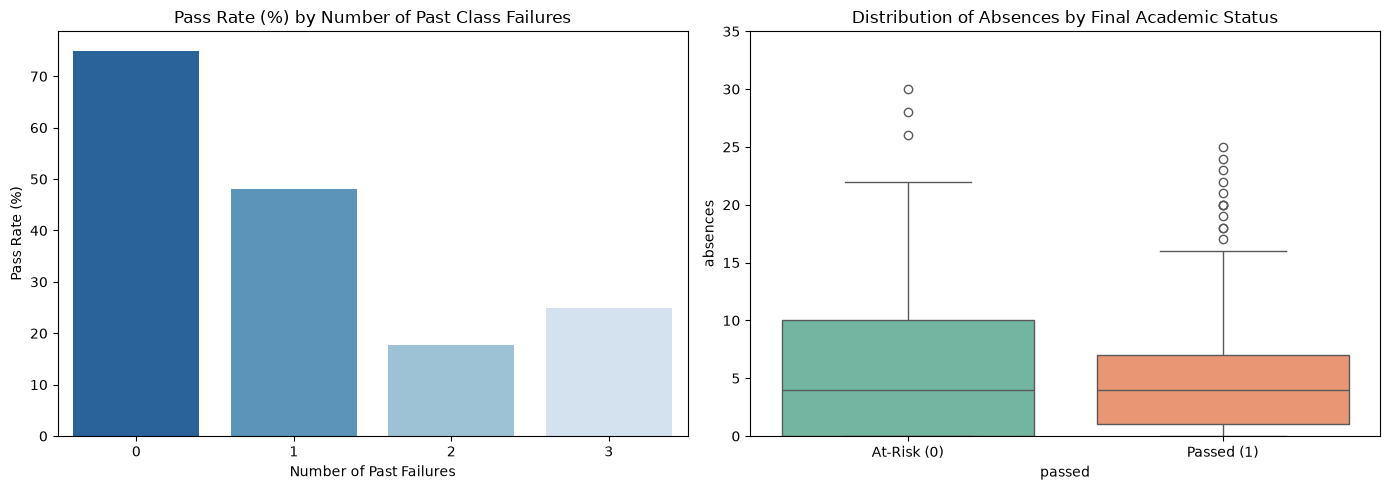

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Past failures vs Passing Rate
failure_pass_rate = df.groupby("failures")["passed"].mean() * 100
sns.barplot(x=failure_pass_rate.index, y=failure_pass_rate.values, ax=axes[0], palette="Blues_r")
axes[0].set_title("Pass Rate (%) by Number of Past Class Failures")
axes[0].set_ylabel("Pass Rate (%)")
axes[0].set_xlabel("Number of Past Failures")

# 2. Absences distribution: Passing vs At-Risk
sns.boxplot(x="passed", y="absences", data=df, ax=axes[1], palette="Set2")
axes[1].set_title("Distribution of Absences by Final Academic Status")
axes[1].set_xticklabels(["At-Risk (0)", "Passed (1)"])
axes[1].set_ylim(0, 35)

plt.tight_layout()
plt.show()